# DSC212 – Graph Theory: Research Assignment
## Modularity on the Karate Club Graph — Recursive Spectral Community Detection

**Name:** Pankaj **ID:** IMS25145 **Course:** DSC212 Graph Theory  **Submission:** Jupyter notebook + GitHub repository

---

### What this notebook does

| Task | What we do | Section |
|---|---|---|
| 1 | Implement **recursive spectral modularity partitioning** *from scratch* (NumPy + NetworkX only) | §2 – §4 |
| 2 | **Visualise** the graph after every split (fixed spring layout, colours, node IDs) | §5 |
| 3 | After every split, compute **degree, betweenness, closeness centrality and clustering** | §6 |
| 4 | **Plot the evolution** of every metric for every node across iterations | §7 |
| 5 | Write a **discussion** (every number in it is checked by code) | §8 |
| – | Remarks on the handout's mathematics (where I followed it, and where it is only approximate) | §9 |

### Reference
M. E. J. Newman (2006), *Modularity and community structure in networks*, **PNAS 103(23): 8577–8582**. The modularity matrix, the leading-eigenvector bipartition and the recursive bisection used here are the method described in that paper (as presented in the course handout).

### How to run
`Kernel → Restart & Run All`. No input is needed; every figure is also saved into the `figures/` folder.

## 0. Setup

We only use **NumPy** (matrices and eigenvalues), **NetworkX** (the graph and the four node metrics) and **Matplotlib** (plots).

Two constants are defined once so that the whole notebook uses the same values:

* `EIG_TOL = 1e-8` – a *tolerance* for computer round-off. Computers store decimals approximately, so a number that should be exactly `0` may come out as `0.0000000003`. We treat any value with size ≤ `EIG_TOL` as zero.
* `LAYOUT_SEED = 42` – the random seed for the spring layout, so the picture is the same every time the notebook is run.

In [ ]:
import os
import numpy as np
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

os.makedirs("figures", exist_ok=True)      # folder where all plots are saved

EIG_TOL = 1e-8        # values smaller than this are treated as zero (round-off)
LAYOUT_SEED = 42      # fixed seed -> the same spring layout every run

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "font.size": 10})

print("NumPy", np.__version__, "| NetworkX", nx.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.5.3 | NetworkX 3.7 | Matplotlib 3.11.2


## 1. The data and the matrices

### 1.1 Load the Karate Club graph

`nx.karate_club_graph()` returns Zachary's network: **34 members (nodes)** and **78 friendships (edges)**.
NetworkX numbers the members **0 – 33** (Zachary's paper uses 1 – 34, so *our node 0 is his member 1*). The instructor **"Mr. Hi" is node 0** and the club president/administrator (**"Officer"**) is **node 33**.

> ⚠️ **A pitfall.** In recent NetworkX versions this graph carries a `weight` attribute on its edges (values 1–7). The handout works with the plain 0/1 adjacency matrix, so everywhere below we **ignore the weights** (`weight=None`).

In [ ]:
G = nx.karate_club_graph()

n = G.number_of_nodes()          # number of vertices
m = G.number_of_edges()          # number of edges
print("Nodes n =", n, "| Edges m =", m, "| Connected:", nx.is_connected(G))

# Ground-truth faction of every member (stored by NetworkX in the node attribute 'club')
club = {node: G.nodes[node]["club"] for node in G.nodes()}
print("Mr. Hi's faction:   ", sum(1 for v in club.values() if v == "Mr. Hi"), "members")
print("Officer's faction:  ", sum(1 for v in club.values() if v == "Officer"), "members")

Nodes n = 34 | Edges m = 78 | Connected: True
Mr. Hi's faction:    17 members
Officer's faction:   17 members


### 1.2 Adjacency matrix $A$, degree vector $k$ and modularity matrix $B$

* **Adjacency matrix** $A$ ($n\times n$): $A_{ij}=1$ if members $i$ and $j$ are friends, else $0$.
* **Degree vector** $k$: $k_i=\sum_j A_{ij}$ (number of friends of $i$). Note $\sum_i k_i = 2m$.
* **Modularity matrix**
$$B = A - \frac{k\,k^{\top}}{2m},\qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.$$
  The second term is the number of edges we would *expect* between $i$ and $j$ if the $2m$ edge-ends were paired completely at random (the "null model"). So $B_{ij}>0$ means *"$i$ and $j$ are more connected than chance"*.

In [ ]:
# Adjacency matrix (0/1). nodelist=range(n) fixes the row order to node IDs 0..33.
A = nx.to_numpy_array(G, nodelist=range(n), weight=None)

# Degree vector: sum of every row of A
k = A.sum(axis=1)

# Modularity matrix  B = A - k k^T / (2m)   (np.outer(k, k) is the matrix k k^T)
B = A - np.outer(k, k) / (2 * m)

print("Shape of A, B:", A.shape, B.shape)
print("Sum of degrees =", int(k.sum()), " (should equal 2m =", 2 * m, ")")
print("Degree of Mr. Hi (node 0):", int(k[0]), "| Degree of Officer (node 33):", int(k[33]))

Shape of A, B: (34, 34) (34, 34)
Sum of degrees = 156  (should equal 2m = 156 )
Degree of Mr. Hi (node 0): 16 | Degree of Officer (node 33): 17


### 1.3 Sanity checks of the handout's basic facts

Before trusting the matrix, check three facts proved in the handout:

1. **Proposition 1** – $B$ is real and symmetric.
2. **Proposition 2** – $B\mathbf 1=\mathbf 0$ (every row of $B$ sums to 0), so $0$ is always an eigenvalue of the *global* $B$.
3. **Corollary 1** – putting everybody in one community gives modularity $Q=\frac1{4m}\mathbf 1^\top B\mathbf 1=0$.

In [ ]:
ones = np.ones(n)

print("B symmetric (Proposition 1):          ", np.allclose(B, B.T))
print("Largest |row sum of B| (Proposition 2):", np.abs(B @ ones).max())
print("Q of the trivial partition (Cor. 1):   ", ones @ B @ ones / (4 * m))

assert np.allclose(B, B.T)
assert np.abs(B @ ones).max() < EIG_TOL
assert abs(ones @ B @ ones) < EIG_TOL
print("\nAll three checks passed.")

B symmetric (Proposition 1):           True
Largest |row sum of B| (Proposition 2): 8.881784197001252e-16
Q of the trivial partition (Cor. 1):    8.718097469011646e-18

All three checks passed.


### 1.4 Leading eigenvalue and eigenvector of the global $B$ (the first split)

`np.linalg.eigh` is NumPy's eigen-solver for **symmetric** matrices. It returns real eigenvalues in **increasing** order, so the *last* one is the largest, $\lambda_1$, and the last column of `eigenvectors` is the leading eigenvector $u_1$ (Theorem 1 guarantees real eigenvalues and an orthonormal eigenbasis).

By the Rayleigh–Ritz theorem (Theorem 2), $\max_{\|s\|=1}s^\top Bs=\lambda_1$ is attained at $s=u_1$. We round $u_1$ back to $\pm1$ with the handout's rule: $s_i=+1$ if $(u_1)_i>0$, otherwise $-1$.

In [ ]:
eigenvalues, eigenvectors = np.linalg.eigh(B)      # eigenvalues in increasing order
lambda_1 = eigenvalues[-1]                          # largest eigenvalue
u_1 = eigenvectors[:, -1]                           # its (unit-length) eigenvector

print("Five largest eigenvalues of B:", np.round(eigenvalues[::-1][:5], 4))
print("Number of (numerically) zero eigenvalues:", int(np.sum(np.abs(eigenvalues) < 1e-8)))
print(f"lambda_1 = {lambda_1:.4f}")
print("Rayleigh quotient u1' B u1 =", round(float(u_1 @ B @ u_1), 4), "(equals lambda_1)")

s = np.where(u_1 > 0, 1, -1)                        # threshold the eigenvector
print("\nGroup sizes after thresholding: +1 ->", int(np.sum(s == 1)), "nodes, -1 ->", int(np.sum(s == -1)), "nodes")
print(f"Modularity of this first split  Q = s'Bs / (4m) = {s @ B @ s / (4 * m):.4f}")

Five largest eigenvalues of B: [4.9771 3.0428 2.3202 1.4888 1.4594]
Number of (numerically) zero eigenvalues: 11
lambda_1 = 4.9771
Rayleigh quotient u1' B u1 = 4.9771 (equals lambda_1)

Group sizes after thresholding: +1 -> 16 nodes, -1 -> 18 nodes
Modularity of this first split  Q = s'Bs / (4m) = 0.3715


$\lambda_1>0$, so the whole club *can* be split. The next sections turn this single step into the full recursive algorithm.

## 2. The algorithm, step by step (Task 1)

The recursive procedure for a group of nodes $C$ (starting with $C=V$):

1. Take the block $B^{(C)}$ of the global $B$: only the rows and columns of the nodes in $C$.
2. Find its leading eigenpair $(\lambda_1^{(C)},u_1^{(C)})$.
3. **Stopping rule:** if $\lambda_1^{(C)}\le 0$ → $C$ stays one community.
4. Otherwise split $C$ into $C^+$ (entries $>0$) and $C^-$ (the rest).
5. Repeat on $C^+$ and $C^-$.

Besides the eigenvalue rule, two practical safeguards are added:

* **Empty group:** if all entries of $u_1^{(C)}$ have the same sign, one side would be empty – nothing is actually split, so $C$ is kept whole.
* **Round-off:** "$>0$" and "$\le0$" are tested with the tolerance `EIG_TOL`.

> The block $B^{(C)}$ is taken **from the global $B$** (so it still uses the degrees $k_i$ and the edge count $m$ of the *whole* graph), as stated in Section 3.3 of the handout.

Below, the algorithm is written as small functions, each doing one job.

In [ ]:
def modularity_Q(partition, B, m):
    # Modularity Q of a partition (a list of communities, each a list of node IDs).
    # Q = (1 / 2m) * sum over communities C of  sum_{i,j in C} B_ij.
    # For two communities this equals s'Bs / (4m), the handout's formula (1).
    total = 0.0
    for community in partition:
        block = B[np.ix_(community, community)]   # rows & columns of this community
        total += block.sum()
    return total / (2 * m)


# Quick test: with the +1/-1 vector s from §1.4 the two formulas must agree.
first_partition = [[i for i in range(n) if s[i] == 1], [i for i in range(n) if s[i] == -1]]
print("Q via communities :", round(modularity_Q(first_partition, B, m), 6))
print("Q via s'Bs/(4m)   :", round(float(s @ B @ s / (4 * m)), 6))

Q via communities : 0.371466
Q via s'Bs/(4m)   : 0.371466


In [ ]:
def leading_eigenpair(M):
    # Return (largest eigenvalue, its eigenvector) of a symmetric matrix M.
    M = (M + M.T) / 2                    # remove tiny round-off asymmetry
    values, vectors = np.linalg.eigh(M)  # values in increasing order
    lam = values[-1]
    u = vectors[:, -1]

    # An eigenvector can be returned as u or as -u (both are correct).
    # Fix the sign so that its first non-negligible entry is positive; this only
    # decides which half is called "+" and makes the output reproducible.
    first = np.argmax(np.abs(u) > EIG_TOL)
    if u[first] < 0:
        u = -u
    return lam, u

In [ ]:
def try_split(community, B):
    # Try to split one community. Returns (lambda_1, plus_group, minus_group, reason).
    # plus_group and minus_group are None when the community must NOT be split.
    B_C = B[np.ix_(community, community)]      # restricted modularity matrix B^(C)
    lam, u = leading_eigenpair(B_C)

    # Stopping criterion (Theorem 3): leading eigenvalue <= 0  ->  indivisible.
    # (A single node has B^(C) = [B_ii] = [-k_i^2 / 2m], which is always <= 0, so it stops here too.)
    if lam <= EIG_TOL:
        return lam, None, None, "leading eigenvalue <= 0"

    # Threshold the eigenvector:  +1 if entry > 0, otherwise -1.
    plus_group  = [community[i] for i in range(len(community)) if u[i] >  EIG_TOL]
    minus_group = [community[i] for i in range(len(community)) if u[i] <= EIG_TOL]

    # Guard against an empty group (all entries of u have the same sign).
    if len(plus_group) == 0 or len(minus_group) == 0:
        return lam, None, None, "eigenvector has one sign -> one group would be empty"

    return lam, plus_group, minus_group, "split"

### 2.1 The recursive function

`recursive_bisection` calls `try_split`. If a split happens it

1. replaces the community in the list `partition` by its two halves,
2. gives the halves colours (the "+" half **keeps the parent's colour**, the "−" half gets a **new** colour, so one can follow communities from picture to picture),
3. saves a **snapshot** in the list `history` – the partition, $Q$, $\lambda_1$ and the modularity gain –
4. calls **itself** on the two halves (this is the recursion).

For the record we store two versions of the modularity gain of the split of $C$ into $C^\pm$ (both discussed in §9):

* `dQ_handout` $=\frac1{4m}s^\top B^{(C)}s$ – the formula written in Theorem 3 of the handout,
* `dQ_true` $=Q_{\text{after}}-Q_{\text{before}}$ – the actual change of $Q$, computed directly from the two partitions.

In [ ]:
def recursive_bisection(community, partition, colour_of, history):
    # Recursively split `community`. `partition`, `colour_of` and `history` are updated in place.
    lam, plus_group, minus_group, reason = try_split(community, B)

    # ---- no split possible: report and stop this branch ----------------------
    if plus_group is None:
        print(f"   keep   |C| = {len(community):2d}   lambda_1 = {lam:+.4f}   -> indivisible ({reason})")
        return

    # ---- a split happens -----------------------------------------------------
    Q_before = modularity_Q(partition, B, m)

    # label vector s for this community (+1 for plus_group, -1 for minus_group)
    s_C = np.array([1 if node in plus_group else -1 for node in community])
    B_C = B[np.ix_(community, community)]
    dQ_handout = s_C @ B_C @ s_C / (4 * m)           # handout's Theorem-3 formula
    correction = B_C.sum() / (4 * m)                 # = 1' B^(C) 1 / (4m)  (see §9)

    # replace the community by its two halves at the same position of the list
    position = partition.index(community)
    partition[position:position + 1] = [plus_group, minus_group]

    # colours: "+" half keeps the parent's colour, "-" half gets a new one
    colour_of[tuple(plus_group)] = colour_of[tuple(community)]
    colour_of[tuple(minus_group)] = max(colour_of.values()) + 1

    Q_after = modularity_Q(partition, B, m)
    history.append({
        "iteration": len(history),
        "parent": list(community),
        "plus": plus_group,
        "minus": minus_group,
        "lambda1": float(lam),
        "partition": [list(c) for c in partition],                  # copy of the partition now
        "colours": [colour_of[tuple(c)] for c in partition],        # colour id of each community
        "Q": float(Q_after),
        "dQ_handout": float(dQ_handout),
        "correction": float(correction),
        "dQ_true": float(Q_after - Q_before),
    })
    print(f"   SPLIT  |C| = {len(community):2d}   lambda_1 = {lam:+.4f}   -> {len(plus_group)} + {len(minus_group)} nodes"
          f"   (iteration {len(history) - 1}, Q = {Q_after:.4f})")

    # ---- recursion: try to split both halves ---------------------------------
    recursive_bisection(plus_group, partition, colour_of, history)
    recursive_bisection(minus_group, partition, colour_of, history)

## 3. Run the algorithm on the Karate Club graph

**Iteration 0** is the starting point (the whole club as one community, $Q=0$). Every *successful* split creates the next iteration. The log below shows every decision the algorithm makes, including the groups it refuses to split.

In [ ]:
whole_graph = list(range(n))             # start: everybody in one community
partition = [whole_graph]                # list of communities
colour_of = {tuple(whole_graph): 0}      # colour id of each community

history = [{                             # iteration 0 = before any split
    "iteration": 0, "parent": None, "plus": None, "minus": None,
    "lambda1": float(lambda_1),
    "partition": [list(whole_graph)], "colours": [0],
    "Q": 0.0, "dQ_handout": None, "correction": None, "dQ_true": None,
}]

print("Recursive spectral bisection - decisions in the order they are made:\n")
recursive_bisection(whole_graph, partition, colour_of, history)

n_iterations = len(history)              # iterations 0, 1, ..., n_iterations-1
final_partition = history[-1]["partition"]
print(f"\nFinished: {n_iterations - 1} successful splits -> {len(final_partition)} communities, final Q = {history[-1]['Q']:.4f}")

Recursive spectral bisection - decisions in the order they are made:

   SPLIT  |C| = 34   lambda_1 = +4.9771   -> 16 + 18 nodes   (iteration 1, Q = 0.3715)
   SPLIT  |C| = 16   lambda_1 = +2.9441   -> 10 + 6 nodes   (iteration 2, Q = 0.3898)
   keep   |C| = 10   lambda_1 = +2.5712   -> indivisible (eigenvector has one sign -> one group would be empty)
   SPLIT  |C| =  6   lambda_1 = +2.1480   -> 5 + 1 nodes   (iteration 3, Q = 0.3911)
   keep   |C| =  5   lambda_1 = +2.1470   -> indivisible (eigenvector has one sign -> one group would be empty)
   keep   |C| =  1   lambda_1 = -0.0064   -> indivisible (leading eigenvalue <= 0)
   SPLIT  |C| = 18   lambda_1 = +2.5041   -> 13 + 5 nodes   (iteration 4, Q = 0.4094)
   keep   |C| = 13   lambda_1 = +2.3563   -> indivisible (eigenvector has one sign -> one group would be empty)
   keep   |C| =  5   lambda_1 = +1.8759   -> indivisible (eigenvector has one sign -> one group would be empty)

Finished: 4 successful splits -> 5 communities, final 

In [ ]:
# The final communities (sorted by size) and a connectivity check.
for number, community in enumerate(sorted(final_partition, key=lambda c: (-len(c), c)), start=1):
    connected = nx.is_connected(G.subgraph(community))
    print(f"Community {number}: size {len(community):2d}  connected={connected}  nodes = {sorted(community)}")

# Independent check of the final modularity with NetworkX's own formula (used ONLY as a check;
# weight=None because the handout uses the unweighted graph).
Q_networkx = nx.community.modularity(G, [set(c) for c in final_partition], weight=None)
print(f"\nQ from my function: {history[-1]['Q']:.6f}   Q from NetworkX (check): {Q_networkx:.6f}")
assert abs(history[-1]["Q"] - Q_networkx) < 1e-10

# every node is in exactly one community
all_nodes = sorted(v for c in final_partition for v in c)
assert all_nodes == list(range(n))
print("Every node belongs to exactly one community: OK")

Community 1: size 13  connected=True  nodes = [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 2: size 10  connected=True  nodes = [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 3: size  5  connected=True  nodes = [4, 5, 6, 10, 16]
Community 4: size  5  connected=True  nodes = [24, 25, 27, 28, 31]
Community 5: size  1  connected=True  nodes = [11]

Q from my function: 0.409435   Q from NetworkX (check): 0.409435
Every node belongs to exactly one community: OK


### 3.1 Does the first split recover the real split of the club?

The first split is the one the handout asks us to compare with history. We compare its two groups with the ground-truth factions (`Mr. Hi` vs `Officer`) stored in the graph.

In [ ]:
first_split = history[1]
group_a, group_b = first_split["plus"], first_split["minus"]

def faction_counts(group):
    hi = sum(1 for v in group if club[v] == "Mr. Hi")
    return hi, len(group) - hi

for name, group in [("Group A (+)", group_a), ("Group B (-)", group_b)]:
    hi, off = faction_counts(group)
    print(f"{name}: {len(group):2d} nodes -> {hi:2d} of Mr. Hi, {off:2d} of Officer")

# misclassified members: assign each group to the faction it mostly contains
majority_a = "Mr. Hi" if faction_counts(group_a)[0] >= faction_counts(group_a)[1] else "Officer"
majority_b = "Officer" if majority_a == "Mr. Hi" else "Mr. Hi"
wrong = [v for v in group_a if club[v] != majority_a] + [v for v in group_b if club[v] != majority_b]
print("Members placed on the 'wrong' side compared with the real split:", sorted(wrong))
print(f"Accuracy of the first split: {(n - len(wrong)) / n:.1%}")

Group A (+): 16 nodes -> 16 of Mr. Hi,  0 of Officer
Group B (-): 18 nodes ->  1 of Mr. Hi, 17 of Officer
Members placed on the 'wrong' side compared with the real split: [8]
Accuracy of the first split: 97.1%


## 4. Why the algorithm stops where it does

The table below lists, for every successful split, the leading eigenvalue that allowed it and the resulting modularity. Groups that were **not** split appear in the log above with the reason (for example a leading eigenvalue $\le 0$ or an eigenvector whose entries all have the same sign).

In [ ]:
print(f"{'iter':>4} {'parent size':>11} {'lambda_1':>9} {'split':>9} {'Q after':>8}")
for snap in history[1:]:
    print(f"{snap['iteration']:>4} {len(snap['parent']):>11} {snap['lambda1']:>9.4f} "
          f"{str(len(snap['plus'])) + '+' + str(len(snap['minus'])):>9} {snap['Q']:>8.4f}")

# Modularity must never decrease along the run
Q_values = [snap["Q"] for snap in history]
assert all(Q_values[i] < Q_values[i + 1] for i in range(len(Q_values) - 1))
print("\nModularity strictly increases at every split:", [round(q, 4) for q in Q_values])

iter parent size  lambda_1     split  Q after
   1          34    4.9771     16+18   0.3715
   2          16    2.9441      10+6   0.3898
   3           6    2.1480       5+1   0.3911
   4          18    2.5041      13+5   0.4094

Modularity strictly increases at every split: [0.0, 0.3715, 0.3898, 0.3911, 0.4094]


## 5. Task 2 – Visualise the graph after every split

* **One fixed layout:** `nx.spring_layout(G, seed=42)` is computed **once** and reused, so a node is at the same place in every picture and only the colours change.
* **Colours:** one colour per community (the "+" half keeps the parent's colour, the "−" half gets a new one).
* **Labels:** every node shows its ID.
* **Edges:** grey solid lines are *inside* a community, red dashed lines connect *different* communities (the edges that were "cut").

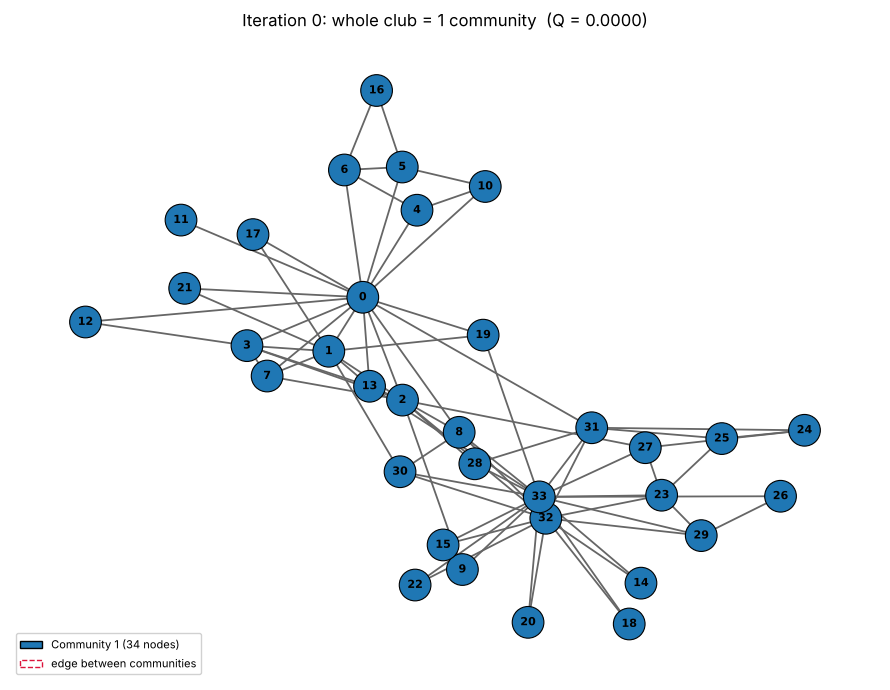

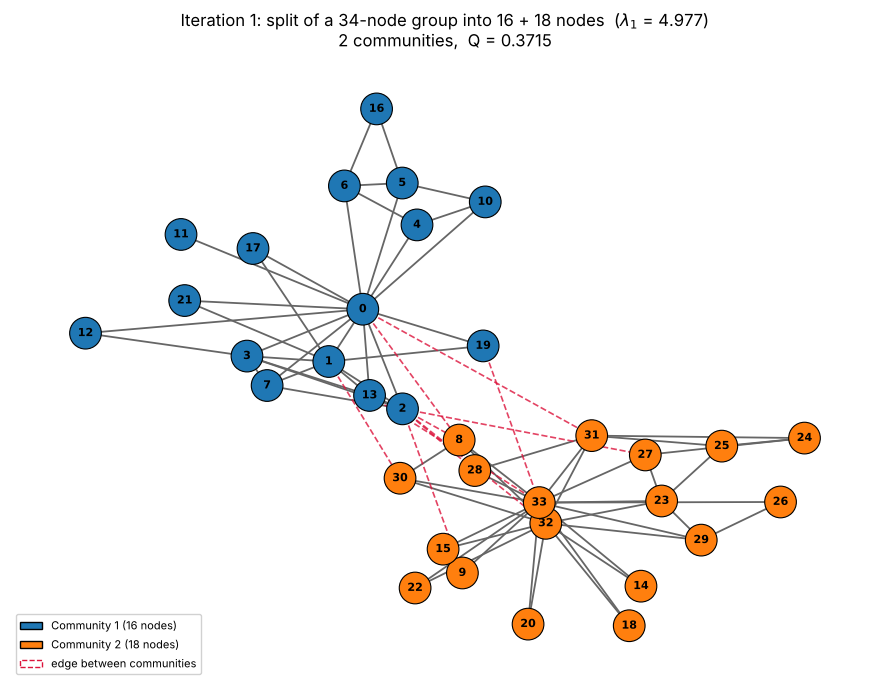

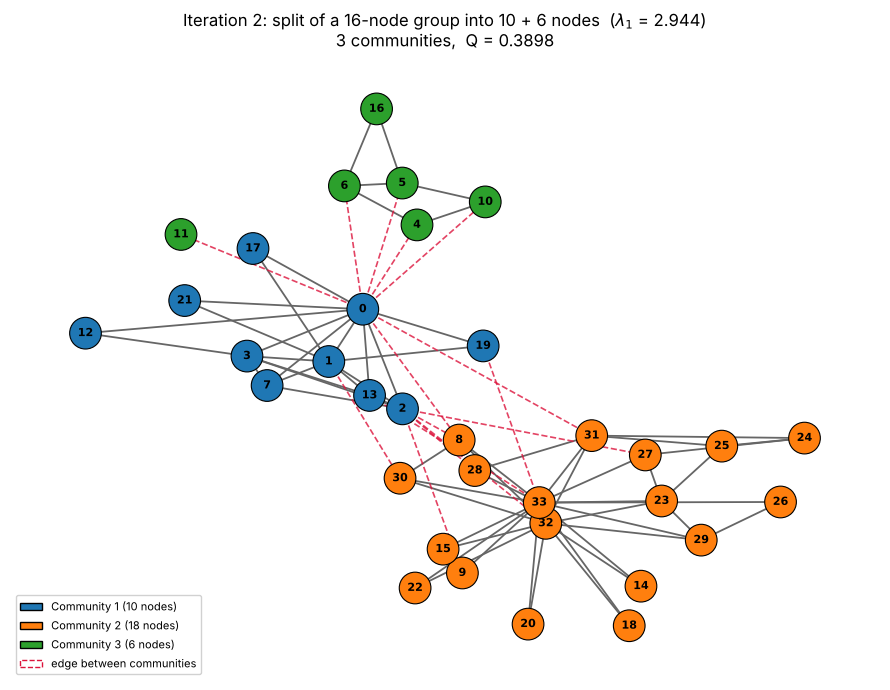

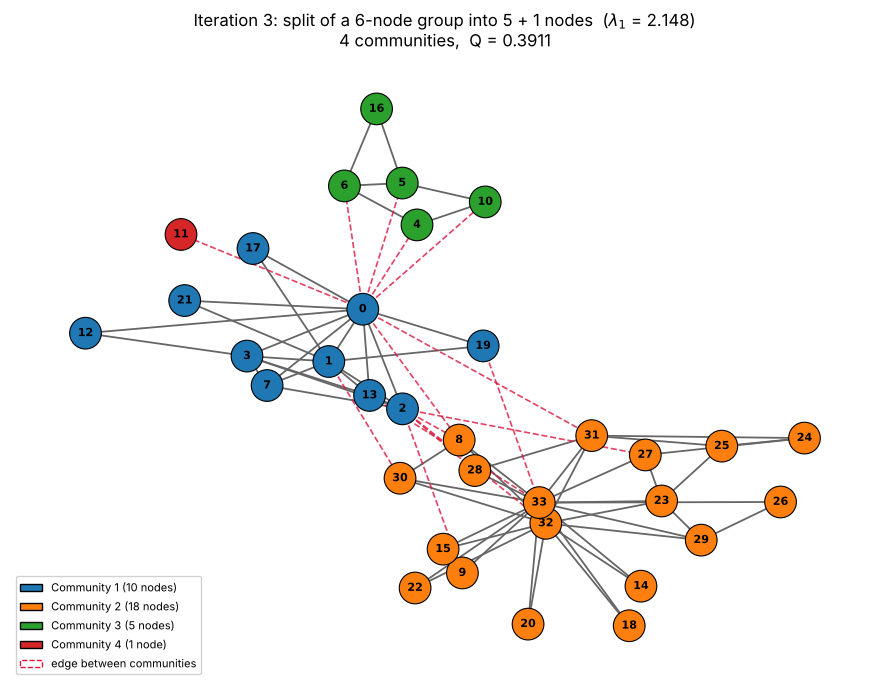

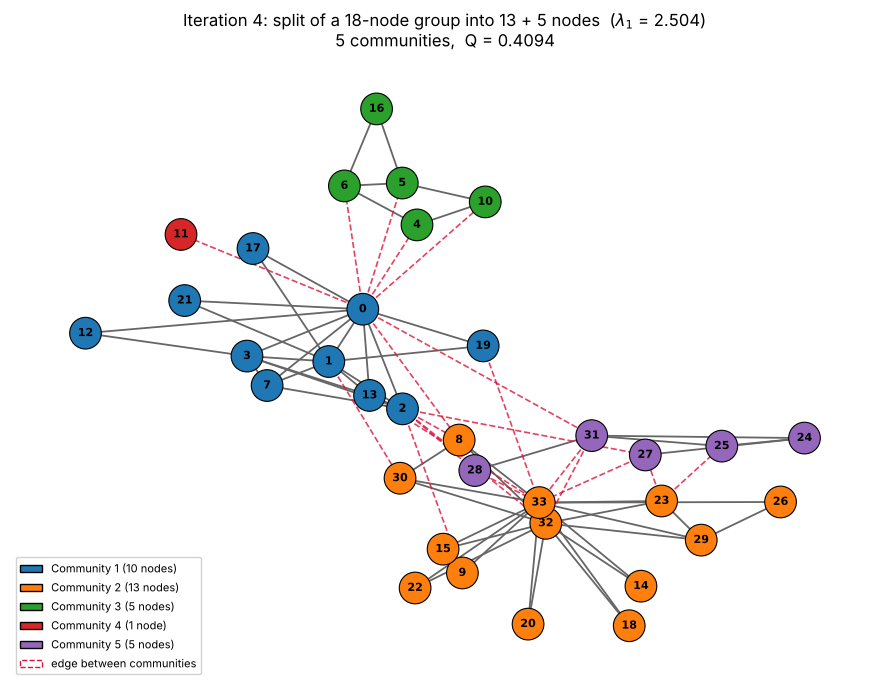

In [ ]:
pos = nx.spring_layout(G, seed=LAYOUT_SEED)     # computed ONCE, reused in every plot
palette = plt.get_cmap("tab10")                 # 10 clearly different colours


def draw_snapshot(snap, ax):
    # Draw the partition stored in `snap` on the axes `ax`.
    # find the colour id of each node
    colour_id = {}
    for community, cid in zip(snap["partition"], snap["colours"]):
        for node in community:
            colour_id[node] = cid

    node_colours = [palette(colour_id[v]) for v in G.nodes()]
    inside  = [(u, v) for u, v in G.edges() if colour_id[u] == colour_id[v]]
    between = [(u, v) for u, v in G.edges() if colour_id[u] != colour_id[v]]

    nx.draw_networkx_edges(G, pos, edgelist=inside, ax=ax, width=1.3, edge_color="0.4")
    nx.draw_networkx_edges(G, pos, edgelist=between, ax=ax, width=1.2, edge_color="crimson",
                           style="dashed", alpha=0.8)
    nx.draw_networkx_nodes(G, pos, node_color=node_colours, node_size=520,
                           edgecolors="black", linewidths=0.8, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, font_weight="bold", ax=ax)

    # legend: one entry per community, ordered by colour id
    entries = sorted(zip(snap["colours"], snap["partition"]), key=lambda pair: pair[0])
    handles = [Patch(facecolor=palette(cid), edgecolor="black",
                     label=f"Community {number} ({len(c)} node{'s' if len(c) != 1 else ''})")
               for number, (cid, c) in enumerate(entries, start=1)]
    handles.append(Patch(facecolor="white", edgecolor="crimson", linestyle="--", label="edge between communities"))
    ax.legend(handles=handles, loc="lower left", fontsize=8, framealpha=0.9)
    ax.set_axis_off()


def snapshot_title(snap):
    if snap["iteration"] == 0:
        return f"Iteration 0: whole club = 1 community  (Q = {snap['Q']:.4f})"
    return (f"Iteration {snap['iteration']}: split of a {len(snap['parent'])}-node group "
            f"into {len(snap['plus'])} + {len(snap['minus'])} nodes  ($\\lambda_1$ = {snap['lambda1']:.3f})\n"
            f"{len(snap['partition'])} communities,  Q = {snap['Q']:.4f}")


for snap in history:
    fig, ax = plt.subplots(figsize=(9, 7))
    draw_snapshot(snap, ax)
    ax.set_title(snapshot_title(snap), fontsize=12)
    fig.tight_layout()
    fig.savefig(f"figures/graph_iteration_{snap['iteration']}.png", dpi=150, bbox_inches="tight")
    plt.show()

### 5.1 All iterations side by side

The same layout and colours make it easy to see how the communities appear.

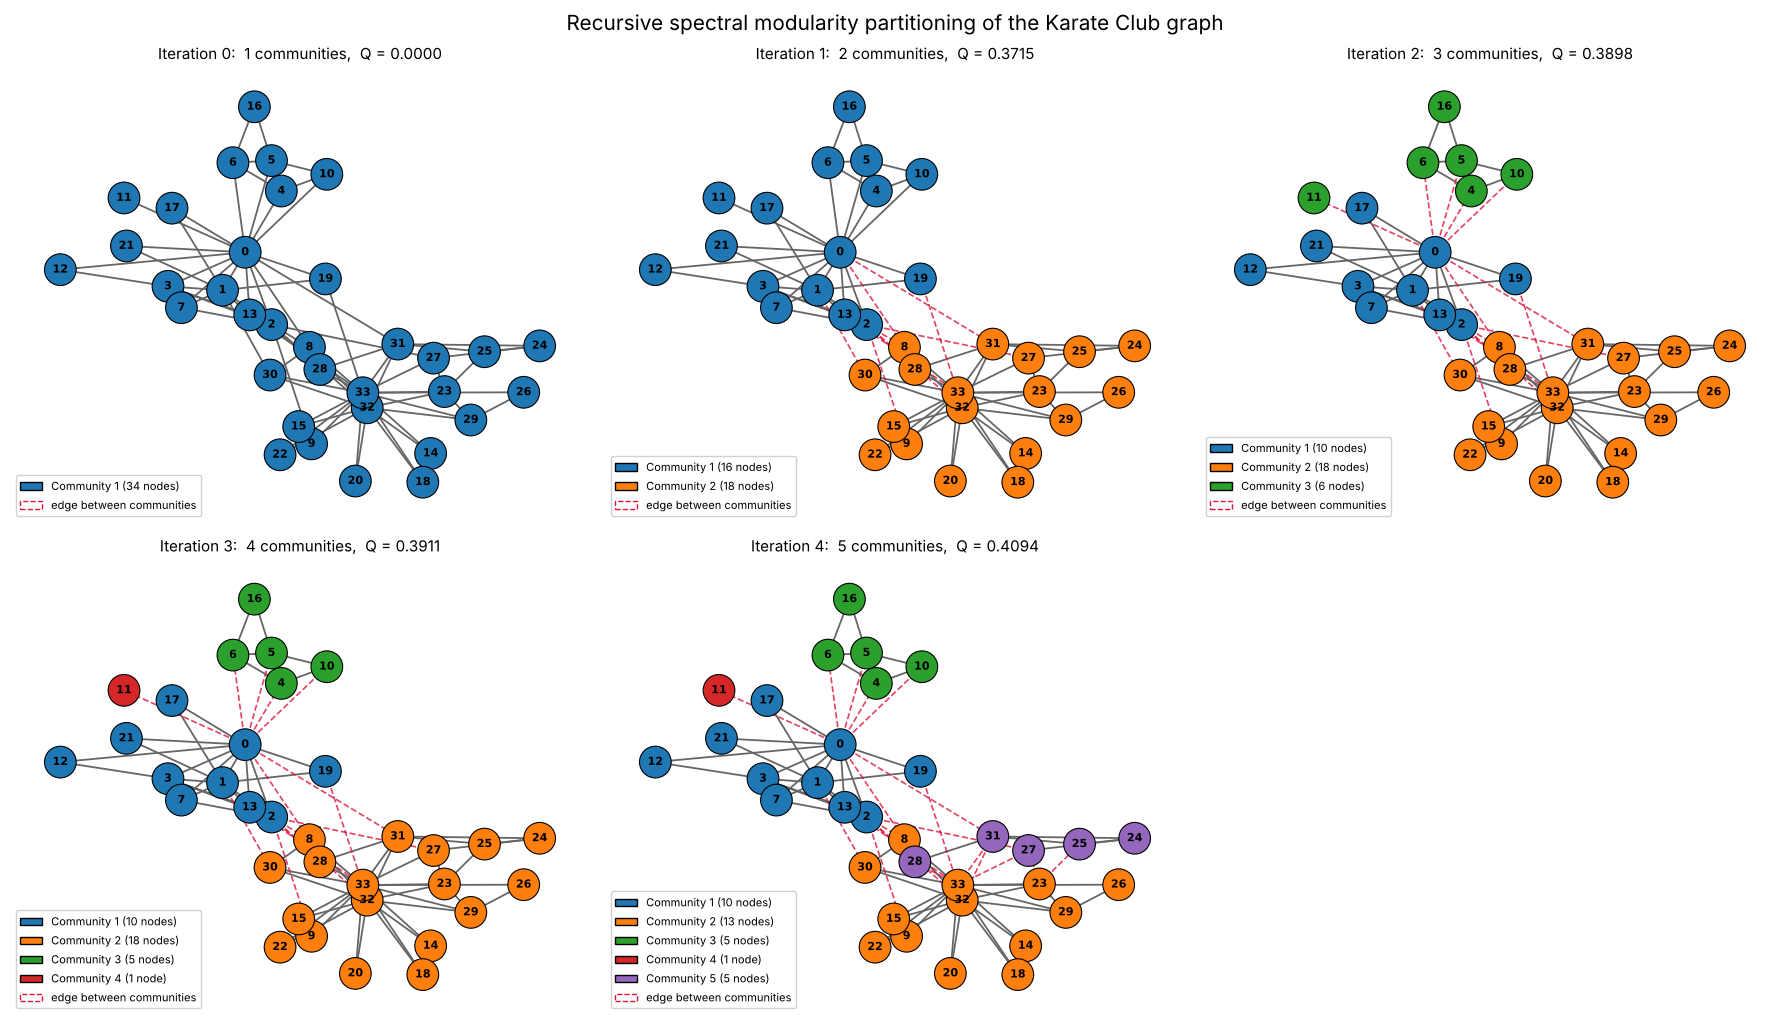

In [ ]:
columns = 3
rows = int(np.ceil(n_iterations / columns))
fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 5.2 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, snap in zip(axes, history):
    draw_snapshot(snap, ax)
    ax.set_title(f"Iteration {snap['iteration']}:  {len(snap['partition'])} communities,  Q = {snap['Q']:.4f}", fontsize=11)
for ax in axes[n_iterations:]:          # hide unused panels
    ax.set_axis_off()

fig.suptitle("Recursive spectral modularity partitioning of the Karate Club graph", fontsize=15)
fig.tight_layout()
fig.savefig("figures/graph_all_iterations.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Task 3 – Network metrics after every split

The four metrics (all computed with NetworkX functions) are

| Metric | Formula | NetworkX function |
|---|---|---|
| Degree centrality | $C_D(i)=\dfrac{k_i}{n-1}$ | `nx.degree_centrality` |
| Betweenness centrality | $C_B(i)=\sum_{s\ne i\ne t}\dfrac{\sigma_{st}(i)}{\sigma_{st}}$ (normalised by NetworkX) | `nx.betweenness_centrality` |
| Closeness centrality | $C_C(i)=\dfrac{n-1}{\sum_{j\ne i}d(i,j)}$ | `nx.closeness_centrality` |
| Clustering coefficient | $C(i)=\dfrac{2T(i)}{k_i(k_i-1)}$ | `nx.clustering` |

### How are the metrics defined "after a split"?

If we simply called these functions on the **whole** graph `G` after each split, the answers would never change (splitting the nodes into colour groups does not change the graph). So that the metrics can *respond* to the community structure, I compute them **inside each community**: for every community $C$ we take the induced subgraph `G.subgraph(C)` (the nodes of $C$ and the edges *between members of $C$*) and apply the NetworkX functions to it. Each node therefore gets the value it has **within its own community**.

* **Iteration 0** = the whole graph, so these are exactly the ordinary whole-graph metrics (checked by an assertion below).
* A node alone in a community has no neighbours, so all four metrics are set to **0** for it (formulas such as $k_i/(n-1)$ are undefined for $n=1$).
* The *final* communities are all connected (§3), but an *intermediate* group may not be: at iteration 2 the 6-node group contains node 11, whose only friend (node 0) lies in the other group, so node 11 is isolated inside it. The cell after the metric computation lists such cases. For disconnected groups NetworkX's closeness uses the Wasserman–Faust scaling (distances to unreachable nodes are ignored and the value is scaled by the fraction of reachable nodes); an isolated node gets closeness 0.
* Because $n-1$ in the formulas becomes the community size minus 1, values are **not on the same scale** at different iterations (e.g. degree centrality is a fraction of the *community*, not of the whole club). This is kept in mind in the discussion.

In [ ]:
METRIC_NAMES = ["degree", "betweenness", "closeness", "clustering"]


def compute_metrics(graph, partition):
    # Compute the four metrics for every node, inside its own community.
    # Returns a dictionary  metric name -> {node: value}.
    result = {name: {} for name in METRIC_NAMES}

    for community in partition:
        if len(community) == 1:                       # lonely node: nothing to measure
            result_values = {name: {community[0]: 0.0} for name in METRIC_NAMES}
        else:
            sub = graph.subgraph(community)           # induced subgraph of this community
            result_values = {
                "degree":      nx.degree_centrality(sub),
                "betweenness": nx.betweenness_centrality(sub),
                "closeness":   nx.closeness_centrality(sub),
                "clustering":  nx.clustering(sub),
            }
        for name in METRIC_NAMES:
            result[name].update(result_values[name])
    return result


# Store the values in dictionaries keyed by iteration number (as the handout asks):
#   metrics_by_iteration["degree"][3][node]  = degree centrality of `node` at iteration 3
metrics_by_iteration = {name: {} for name in METRIC_NAMES}

for snap in history:
    t = snap["iteration"]
    values = compute_metrics(G, snap["partition"])
    for name in METRIC_NAMES:
        metrics_by_iteration[name][t] = values[name]

# Check: at iteration 0 the result must equal the plain whole-graph NetworkX calls.
whole = {"degree": nx.degree_centrality(G), "betweenness": nx.betweenness_centrality(G),
         "closeness": nx.closeness_centrality(G), "clustering": nx.clustering(G)}
for name in METRIC_NAMES:
    for node in range(n):
        assert abs(metrics_by_iteration[name][0][node] - whole[name][node]) < 1e-12
print("Iteration 0 equals the whole-graph NetworkX metrics: OK")

# Convert to arrays for plotting: metric_array[name][t, node]
metric_array = {name: np.array([[metrics_by_iteration[name][t][node] for node in range(n)]
                                for t in range(n_iterations)]) for name in METRIC_NAMES}
print("Stored", len(METRIC_NAMES), "metrics x", n_iterations, "iterations x", n, "nodes.",
      "Array shape per metric:", metric_array["degree"].shape)

# Which communities are NOT connected at some iteration? (closeness needs special care for them)
for snap in history:
    for community in snap["partition"]:
        if len(community) > 1 and not nx.is_connected(G.subgraph(community)):
            isolated = [v for v in community if G.subgraph(community).degree(v) == 0]
            print(f"Iteration {snap['iteration']}: group {sorted(community)} is not connected "
                  f"(nodes with no friend inside the group: {isolated})")

Iteration 0 equals the whole-graph NetworkX metrics: OK
Stored 4 metrics x 5 iterations x 34 nodes. Array shape per metric: (5, 34)
Iteration 2: group [4, 5, 6, 10, 11, 16] is not connected (nodes with no friend inside the group: [11])


### 6.1 The stored values

Rows are nodes, columns are iterations (0 = whole graph, last = final communities).
The column `comm` is the node's final community number (matching the colours/legend order of the last picture).

In [ ]:
# community number of every node in the FINAL partition (1 = biggest community)
final_sorted = sorted(final_partition, key=lambda c: (-len(c), c))
final_community = {node: number for number, c in enumerate(final_sorted, start=1) for node in c}


def print_metric_table(name):
    values = metric_array[name]
    print(f"\n=== {name.upper()} ===")
    print("node comm | " + " ".join(f"{'iter ' + str(t):>7}" for t in range(n_iterations)))
    for node in range(n):
        row = " ".join(f"{values[t, node]:>7.4f}" for t in range(n_iterations))
        print(f"{node:>4} {final_community[node]:>4} | {row}")


for metric_name in METRIC_NAMES:
    print_metric_table(metric_name)


=== DEGREE ===
node comm |  iter 0  iter 1  iter 2  iter 3  iter 4
   0    2 |  0.4848  0.9333  1.0000  1.0000  1.0000
   1    2 |  0.2727  0.5333  0.8889  0.8889  0.8889
   2    2 |  0.3030  0.3333  0.5556  0.5556  0.5556
   3    2 |  0.1818  0.4000  0.6667  0.6667  0.6667
   4    3 |  0.0909  0.2000  0.4000  0.5000  0.5000
   5    3 |  0.1212  0.2667  0.6000  0.7500  0.7500
   6    3 |  0.1212  0.2667  0.6000  0.7500  0.7500
   7    2 |  0.1212  0.2667  0.4444  0.4444  0.4444
   8    1 |  0.1515  0.1765  0.1765  0.1765  0.2500
   9    1 |  0.0606  0.0588  0.0588  0.0588  0.0833
  10    3 |  0.0909  0.2000  0.4000  0.5000  0.5000
  11    5 |  0.0303  0.0667  0.0000  0.0000  0.0000
  12    2 |  0.0606  0.1333  0.2222  0.2222  0.2222
  13    2 |  0.1515  0.2667  0.4444  0.4444  0.4444
  14    1 |  0.0606  0.1176  0.1176  0.1176  0.1667
  15    1 |  0.0606  0.1176  0.1176  0.1176  0.1667
  16    3 |  0.0606  0.1333  0.4000  0.5000  0.5000
  17    2 |  0.0606  0.1333  0.2222  0.2222  0.2

## 7. Task 4 – Evolution of the metrics across iterations

For each metric there is one figure with two panels:

* **Left – line plot:** one line per node (all 34), coloured by the node's **final** community. The most interesting nodes (top-3 at the start and top-3 at the end) are drawn thicker and labelled with their **node ID**.
* **Right – heat map:** every node ID on the vertical axis, iterations on the horizontal axis, colour = metric value. This makes every node readable.

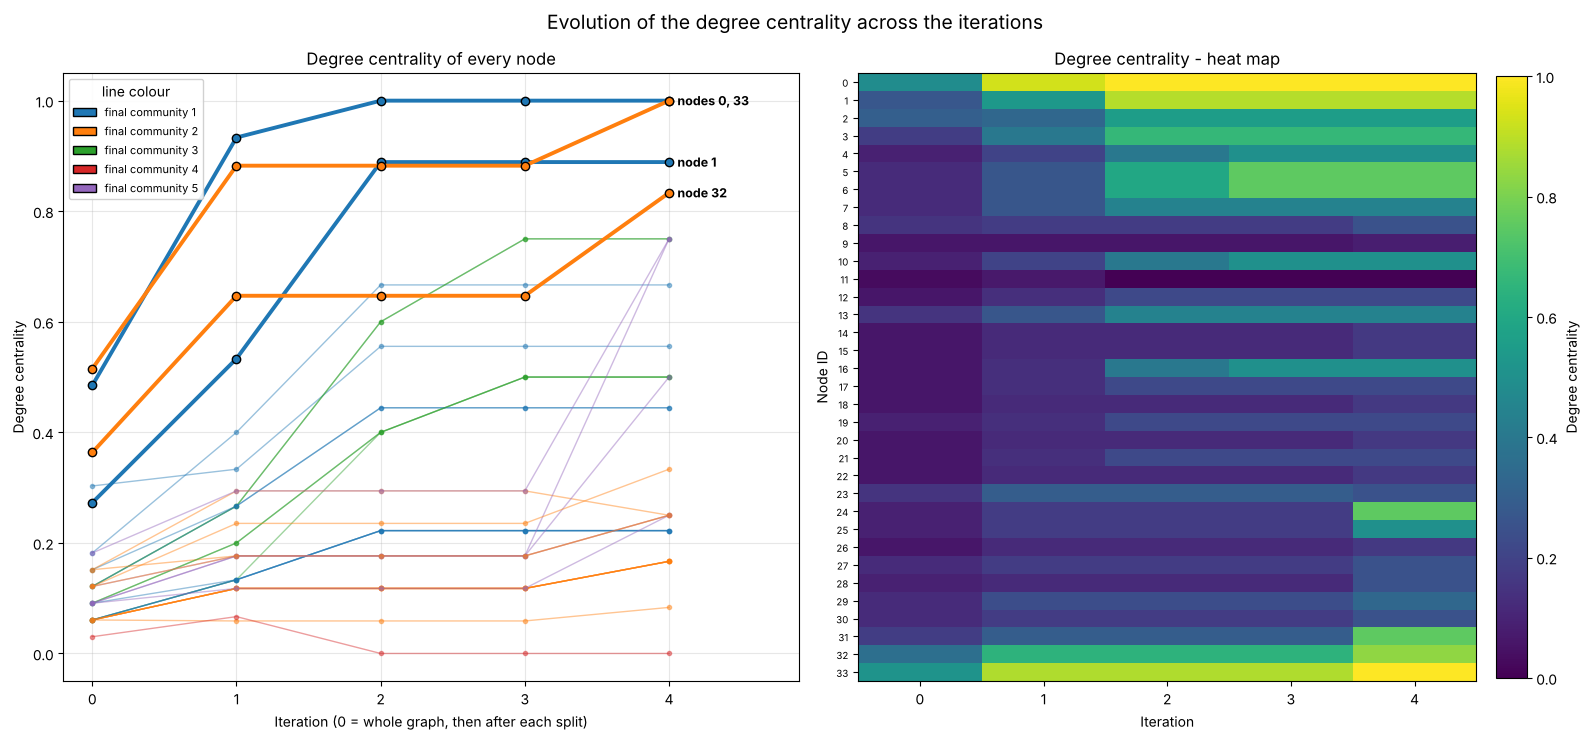

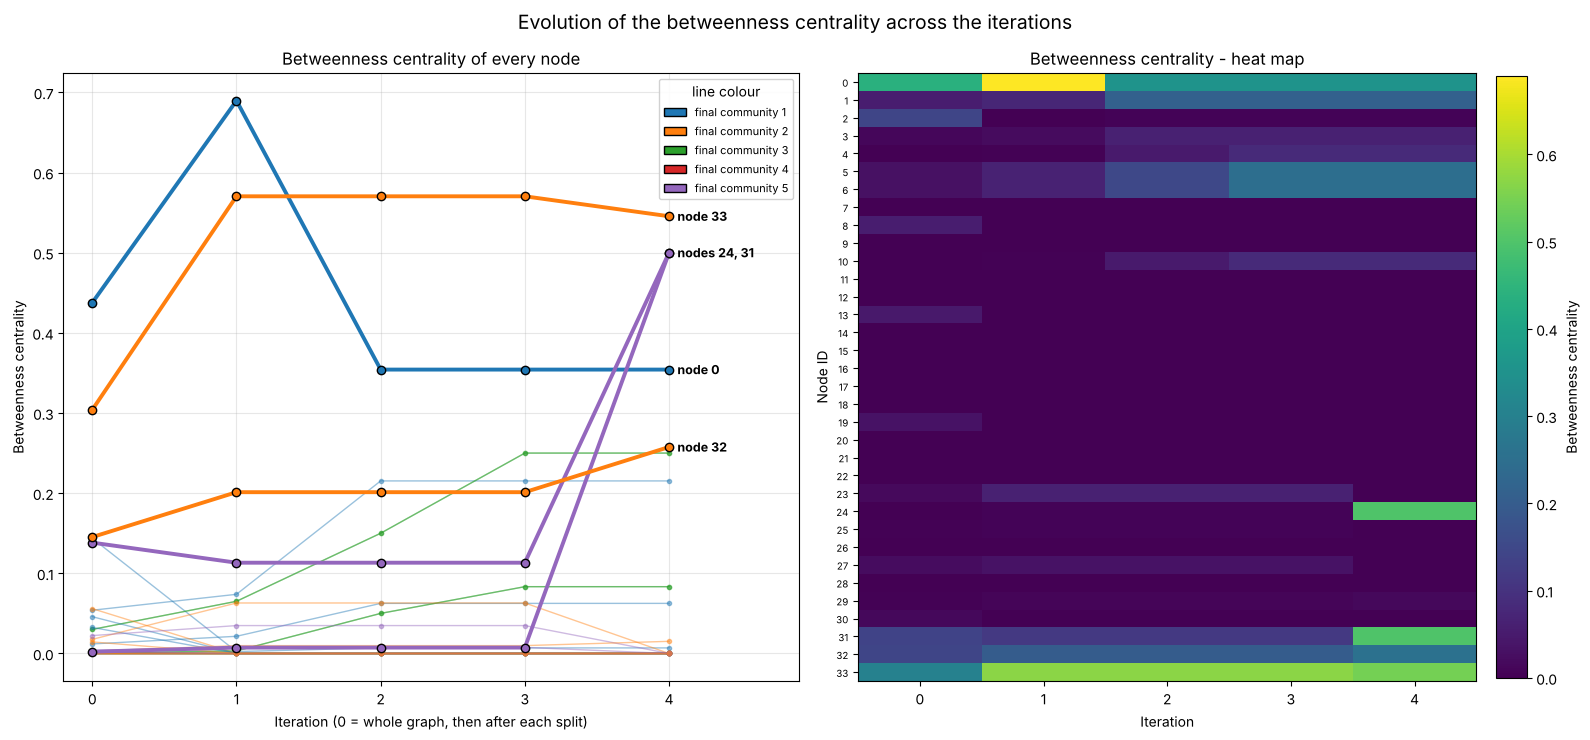

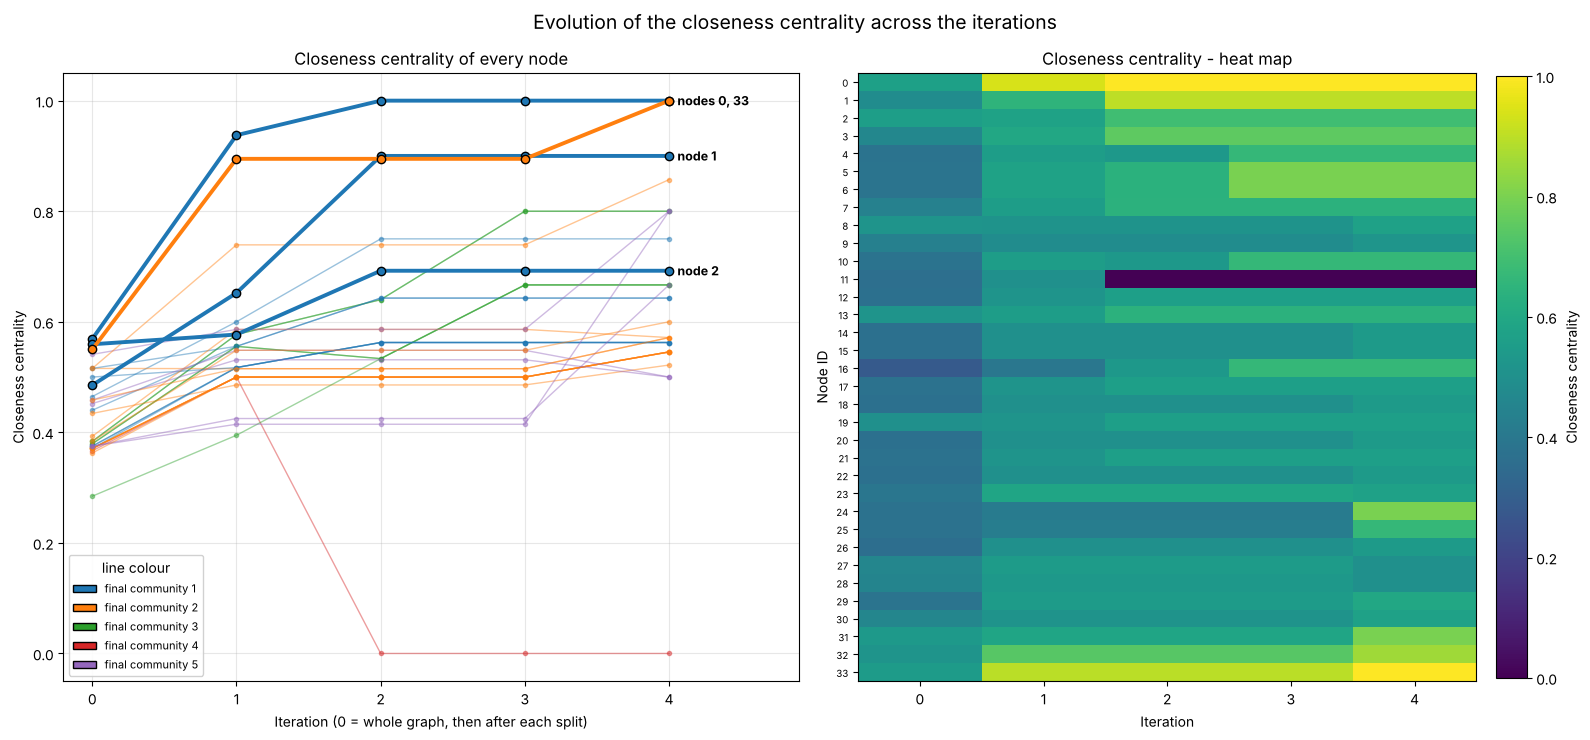

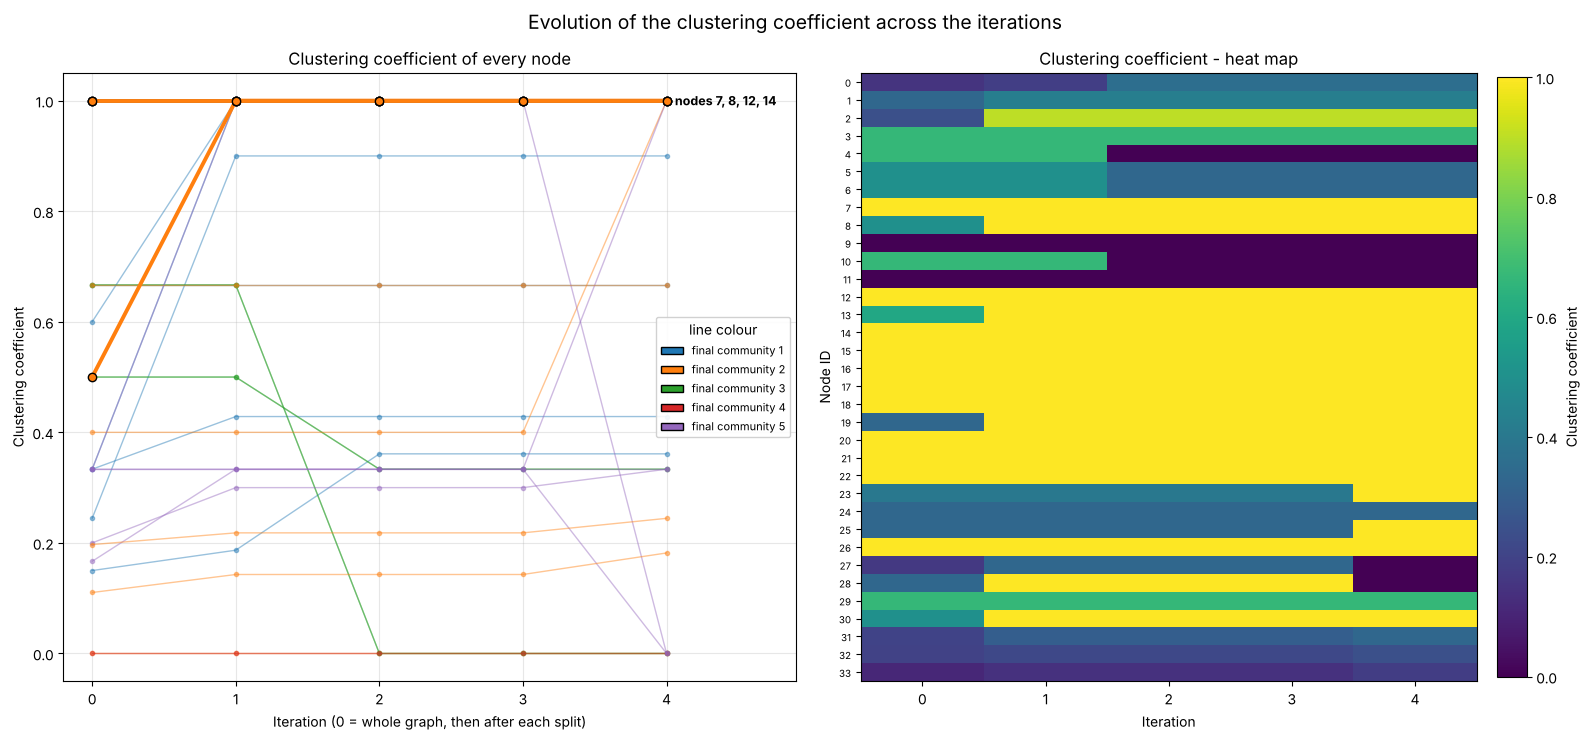

In [ ]:
METRIC_TITLES = {
    "degree": "Degree centrality",
    "betweenness": "Betweenness centrality",
    "closeness": "Closeness centrality",
    "clustering": "Clustering coefficient",
}

# colour of each node = colour of its community in the last iteration
final_snapshot = history[-1]
final_colour_of_node = {}
for community, cid in zip(final_snapshot["partition"], final_snapshot["colours"]):
    for node in community:
        final_colour_of_node[node] = palette(cid)


def plot_metric_evolution(name):
    values = metric_array[name]                     # shape (iterations, nodes)
    iterations = np.arange(n_iterations)

    # nodes to highlight: top-3 at the first and at the last iteration
    top_first = list(np.argsort(-values[0], kind="stable")[:3])
    top_last = list(np.argsort(-values[-1], kind="stable")[:3])
    highlight = sorted(set(int(v) for v in top_first + top_last))

    fig, (ax_line, ax_heat) = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={"width_ratios": [1.1, 1]})

    # ---- left: line plot of all nodes ---------------------------------------
    for node in range(n):
        if node in highlight:
            continue
        ax_line.plot(iterations, values[:, node], color=final_colour_of_node[node], lw=1, alpha=0.45, marker="o", ms=3)
    for node in highlight:
        ax_line.plot(iterations, values[:, node], color=final_colour_of_node[node], lw=2.8, marker="o", ms=6,
                     markeredgecolor="black")
    # one text label per distinct end value (nodes with the same end value share a label)
    labels_at_end = {}
    for node in highlight:
        labels_at_end.setdefault(round(float(values[-1, node]), 6), []).append(node)
    for end_value, group in labels_at_end.items():
        text = ("node " if len(group) == 1 else "nodes ") + ", ".join(str(v) for v in group)
        ax_line.annotate(text, (iterations[-1], end_value), xytext=(6, 0),
                         textcoords="offset points", va="center", fontsize=9, fontweight="bold")

    ax_line.set_xticks(iterations)
    ax_line.set_xlim(-0.2, n_iterations - 1 + 0.9)
    ax_line.set_xlabel("Iteration (0 = whole graph, then after each split)")
    ax_line.set_ylabel(METRIC_TITLES[name])
    ax_line.set_title(f"{METRIC_TITLES[name]} of every node")
    ax_line.grid(alpha=0.3)
    legend_items = [Patch(facecolor=palette(cid), edgecolor="black", label=f"final community {number}")
                    for number, (cid, c) in enumerate(
                        sorted(zip(final_snapshot["colours"], final_snapshot["partition"]), key=lambda p: p[0]), start=1)]
    ax_line.legend(handles=legend_items, loc="best", fontsize=8, title="line colour", framealpha=0.9)

    # ---- right: heat map with all node IDs ----------------------------------
    image = ax_heat.imshow(values.T, aspect="auto", cmap="viridis")
    ax_heat.set_xticks(iterations)
    ax_heat.set_yticks(range(n))
    ax_heat.set_yticklabels(range(n), fontsize=7)
    ax_heat.set_xlabel("Iteration")
    ax_heat.set_ylabel("Node ID")
    ax_heat.set_title(f"{METRIC_TITLES[name]} - heat map")
    fig.colorbar(image, ax=ax_heat, fraction=0.045, pad=0.03, label=METRIC_TITLES[name])

    fig.suptitle(f"Evolution of the {METRIC_TITLES[name].lower()} across the iterations", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"figures/evolution_{name}.png", dpi=130, bbox_inches="tight")
    plt.show()


for metric_name in METRIC_NAMES:
    plot_metric_evolution(metric_name)

### 7.1 Average value of every metric per iteration

A compact summary: the mean over all 34 nodes. It shows the overall effect of splitting the network.

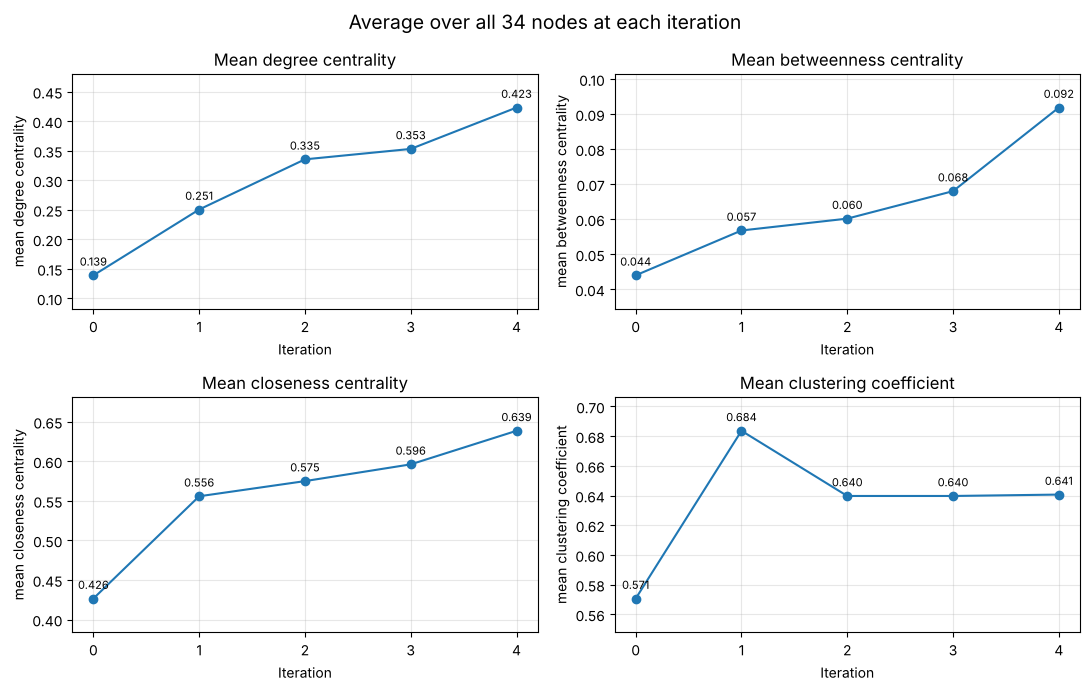

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.ravel(), METRIC_NAMES):
    mean_values = metric_array[name].mean(axis=1)
    ax.plot(range(n_iterations), mean_values, marker="o", color="tab:blue")
    for t, value in enumerate(mean_values):
        ax.annotate(f"{value:.3f}", (t, value), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_xticks(range(n_iterations))
    ax.set_xlabel("Iteration")
    ax.set_ylabel(f"mean {METRIC_TITLES[name].lower()}")
    ax.set_title(f"Mean {METRIC_TITLES[name].lower()}")
    ax.grid(alpha=0.3)
    ax.margins(y=0.2)
fig.suptitle("Average over all 34 nodes at each iteration", fontsize=14)
fig.tight_layout()
fig.savefig("figures/evolution_mean_metrics.png", dpi=130, bbox_inches="tight")
plt.show()

### 7.2 Evidence used in the discussion

The next cell prints the facts that the discussion in §8 is based on (rankings, bridge nodes, changes). The discussion only quotes numbers printed here.

In [ ]:
def top_nodes(values, how_many=5):
    # IDs of the `how_many` largest entries (ties broken by node ID), with their values.
    order = np.argsort(-values, kind="stable")[:how_many]
    return [(int(v), round(float(values[v]), 4)) for v in order]


print("TOP-5 NODES PER METRIC AT EVERY ITERATION  (node, value)")
for name in METRIC_NAMES:
    print(f"\n{METRIC_TITLES[name]}")
    for t in range(n_iterations):
        print(f"  iter {t}: {top_nodes(metric_array[name][t])}")

# ---- bridge candidates: edges between different communities in the FINAL partition ----
community_of = {node: number for number, c in enumerate(final_sorted, start=1) for node in c}
cut_edges = [(u, v) for u, v in G.edges() if community_of[u] != community_of[v]]
cross_count = {node: 0 for node in range(n)}
for u, v in cut_edges:
    cross_count[u] += 1
    cross_count[v] += 1
print("\nEdges between different final communities:", len(cut_edges), "of", m)
print("Nodes with the most edges to OTHER communities (node, #cross edges, degree):")
for node in sorted(range(n), key=lambda v: (-cross_count[v], v))[:8]:
    print(f"   node {node:>2}: {cross_count[node]} cross edges, degree {int(k[node])}, community {community_of[node]}")

# ---- edges cut by the very first split ----
first_cut = [(u, v) for u, v in G.edges() if (u in group_a) != (v in group_a)]
print("\nEdges cut by the first split:", len(first_cut))
ends = {}
for u, v in first_cut:
    ends[u] = ends.get(u, 0) + 1
    ends[v] = ends.get(v, 0) + 1
print("Endpoints of those edges (node: how many cut edges):", dict(sorted(ends.items(), key=lambda kv: (-kv[1], kv[0]))))

# ---- biggest changes between iteration 0 and the last iteration ----
print("\nBIGGEST CHANGES  (iteration 0 -> last iteration)")
for name in METRIC_NAMES:
    change = metric_array[name][-1] - metric_array[name][0]
    up = [(int(v), round(float(change[v]), 4)) for v in np.argsort(-change, kind="stable")[:3]]
    down = [(int(v), round(float(change[v]), 4)) for v in np.argsort(change, kind="stable")[:3]]
    print(f"  {name:<12} largest increases {up}   largest decreases {down}")

print("\nMean values per iteration:")
for name in METRIC_NAMES:
    print(f"  {name:<12}", np.round(metric_array[name].mean(axis=1), 4))

TOP-5 NODES PER METRIC AT EVERY ITERATION  (node, value)

Degree centrality
  iter 0: [(33, 0.5152), (0, 0.4848), (32, 0.3636), (2, 0.303), (1, 0.2727)]
  iter 1: [(0, 0.9333), (33, 0.8824), (32, 0.6471), (1, 0.5333), (3, 0.4)]
  iter 2: [(0, 1.0), (1, 0.8889), (33, 0.8824), (3, 0.6667), (32, 0.6471)]
  iter 3: [(0, 1.0), (1, 0.8889), (33, 0.8824), (5, 0.75), (6, 0.75)]
  iter 4: [(0, 1.0), (33, 1.0), (1, 0.8889), (32, 0.8333), (5, 0.75)]

Betweenness centrality
  iter 0: [(0, 0.4376), (33, 0.3041), (32, 0.1452), (2, 0.1437), (31, 0.1383)]
  iter 1: [(0, 0.6897), (33, 0.5703), (32, 0.2012), (31, 0.1132), (1, 0.0738)]
  iter 2: [(33, 0.5703), (0, 0.3542), (1, 0.2153), (32, 0.2012), (5, 0.15)]
  iter 3: [(33, 0.5703), (0, 0.3542), (5, 0.25), (6, 0.25), (1, 0.2153)]
  iter 4: [(33, 0.5455), (24, 0.5), (31, 0.5), (0, 0.3542), (32, 0.2576)]

Closeness centrality
  iter 0: [(0, 0.569), (2, 0.5593), (33, 0.55), (31, 0.541), (8, 0.5156)]
  iter 1: [(0, 0.9375), (33, 0.8947), (32, 0.7391), (1, 

## 8. Task 5 – Discussion

*How to read the numbers:* iteration 0 is the whole club; at later iterations every metric is measured **inside the node's own community** (§6), so values at different iterations are on different scales. All numbers quoted below are printed in §6–§7.2 and re-checked by the code cell that follows this discussion.

### 8.1 Which nodes consistently remain central?

* **Nodes 33 (the Officer) and 0 (Mr. Hi) are the central nodes of the club at every stage.** At iteration 0 they have the highest degree centrality (0.5152 and 0.4848) and the highest betweenness (0.4376 for node 0, 0.3041 for node 33; the next node, 32, has only 0.1452). They stay among the top three nodes by degree *and* by closeness at **every** iteration. In the final communities each of them is a friend of every other member of its group: degree and closeness are both 1.0 (node 0 already reaches 1.0 at iteration 2).
* Betweenness: nodes 0 and 33 are the top two at iterations 0–3. At iteration 4 node 33 is still first (0.5455) but nodes 24 and 31 (0.5 each) overtake node 0 (0.3542); they are the connectors of a tiny 5-node community, where a single path weighs a lot (a scale effect, see 8.3).
* **Second tier:** node 32 is the third most connected node at iterations 0 and 1 (degree 0.3636 and 0.6471); node 1 is in the top three by degree at iterations 2, 3 and 4 (0.8889), i.e. it is the second hub of Mr. Hi's group.

### 8.2 Which nodes act as bridges between communities?

* **Node 2** is the clearest bridge: 5 of the 10 edges cut by the first split end at node 2. In the whole graph it has the 4th highest betweenness (0.1437), but once the factions are separated its betweenness collapses to 0.0024 (iteration 1), because the shortest paths that crossed the boundary are gone.
* **Nodes 0 and 33** are leaders *and* brokers. Among the 21 edges (26.9 % of all 78) that join different final communities, node 0 owns 7 (of its 16 friendships), node 2 owns 5 (of 10), node 33 owns 5 (of 17), and nodes 27 and 31 own 3 each (of 4 and 6).
* **Nodes 8, 13, 19 and 30** had a small positive betweenness in the whole graph (0.0559, 0.0459, 0.0325 and 0.0144) and exactly 0 after the first split: their only brokerage was linking the two factions, and those links were cut.
* **Node 8** is the one member the first split misplaces: it has friends on both sides (nodes 0 and 2 on Mr. Hi's side; 30, 32 and 33 on the Officer's side) – a typical boundary node.

### 8.3 How does splitting change the centrality scores?

* **Degree and closeness rise for almost everybody.** The means increase at every iteration: degree 0.1390 → 0.2505 → 0.3355 → 0.3531 → 0.4232, closeness 0.4265 → 0.5558 → 0.5749 → 0.5961 → 0.6385. This is mainly a *scale effect*: inside a community the denominator is the community size − 1, not 33, and distances are measured only among community mates. Example: node 0 goes from degree centrality 0.4848 (16 of 33 possible friends) to 1.0 (9 of 9). A higher number therefore does **not** mean the node became more important in the club.
* **Betweenness concentrates in the hubs, then redistributes.** Node 33 goes 0.3041 → 0.5703 (iteration 1) → 0.5455 (final); node 0 goes 0.4376 → 0.6897 (iteration 1) but falls to 0.3542 at iteration 2, when the group containing nodes 4, 5, 6, 10, 11 and 16 – who relied on node 0 to reach the rest – is split off. The largest increases between iteration 0 and the end are for nodes 24 (+0.4978), 31 (+0.3617) and 33 (+0.2414); the largest decreases for nodes 2 (−0.1367), 0 (−0.0835) and 8 (−0.0559). Splitting therefore removes the brokerage of boundary nodes (2, 8, …) and promotes the internal connectors of small groups.
* **Node 11** knows only node 0. After node 11 is separated from node 0 it is isolated inside its group, so its degree falls from 0.0303 to 0 and its closeness from 0.3667 to 0 (iteration 2): the "largest closeness decrease" is partly an artefact of this convention (isolated node → 0).
* **Closeness at iteration 2 is not monotone for nodes 4 and 10** (0.5556 → 0.5333 → 0.6667 at iterations 1, 2, 3): the 6-node group at iteration 2 is disconnected (node 11 is isolated in it), which lowers the Wasserman–Faust-scaled closeness of its other members; it recovers as soon as node 11 is separated.

### 8.4 How do the clustering coefficients change?

* **The mean clustering rises when the club is first split** (0.5706 → 0.6836): cutting the edges between the two factions removes "open" triads, so neighbours that remain are more often friends with each other. Examples: node 2 (0.2444 → 0.9), node 19 (0.3333 → 1.0), node 13 (0.6 → 1.0), node 8, node 30 (0.5 → 1.0) and node 28 (0.3333 → 1.0).
* **It can also fall** when the lost neighbour was the one closing the triangles: nodes 4 and 10 drop from 0.6667 to 0 and nodes 5 and 6 from 0.5 to 0.3333 at iteration 2, because their link to node 0 is cut; the mean goes down to 0.6397, stays there at iteration 3 and ends at 0.6407. At the last split, nodes 28 (1.0 → 0) and 27 (0.3333 → 0) end up with fewer than two friends inside their group, for which NetworkX defines clustering as 0.
* **Tightly knit members never change:** every node with clustering 1.0 at iteration 0 (7, 12, 14, 15, 16, 17, 18, 20, 21, 22, 26) still has 1.0 at the end – they sit deep inside a community.
* **Hubs have low clustering** – the price of connecting many unconnected people: at iteration 0 node 0 has 0.15, node 33 has 0.1103 and node 32 has 0.197; in the final communities they still have only 0.3611, 0.1818 and 0.2444.

### 8.5 What do the results tell us about the Karate Club network?

* The very first split (16 + 18 members, Q = 0.3715) already recovers the real split of the club for 33 of the 34 members (97.1 %); only node 8 is misplaced. So the friendship network recorded *before* the dispute really did contain the fault line of the later split – as Zachary observed.
* The club is organised around **two hubs**, Mr. Hi (0) and the Officer (33), who dominate degree, closeness and betweenness; a few boundary members (2, 8, 13, 19, 30, 31, 32, …) provide the links between the two sides. Only 10 of the 78 edges (12.8 %) cross the first split.
* Continuing the recursion gives **5 communities with Q = 0.4094**, higher than the Q = 0.3582 of the two true factions. Modularity rewards well-defined sub-groups (e.g. the group {4, 5, 6, 10, 16} around Mr. Hi, the group {24, 25, 27, 28, 31}), so a higher Q does not mean "more correct" than the historical split, only that the network has finer structure inside each faction. Node 11 (a member whose only friend is node 0) is left alone as a community of one.
* **Caveats:** the metrics are measured inside the communities, hence the changes of scale; small communities (5 nodes) produce extreme values; and the method follows the handout's block matrix $B^{(C)}$, whose gain formula is only approximate for sub-groups (§9).

In [ ]:
# Re-check every number quoted in the discussion (§8). If a claim is wrong, the assertion fails.
def r4(x):
    return round(float(x), 4)

def check(label, condition):
    assert condition, "CLAIM FAILED: " + label
    print("OK  ", label)

deg, bet, clo, clu = (metric_array[x] for x in METRIC_NAMES)
top = lambda arr, t, j: [int(v) for v in np.argsort(-arr[t], kind="stable")[:j]]
last = n_iterations - 1

# ---- 8.1 consistently central nodes
check("iteration 0: top-2 degree are nodes 33, 0 (0.5152, 0.4848)",
      top(deg, 0, 2) == [33, 0] and (r4(deg[0, 33]), r4(deg[0, 0])) == (0.5152, 0.4848))
check("iteration 0: top-2 betweenness are 0, 33 (0.4376, 0.3041); next is node 32 (0.1452)",
      top(bet, 0, 3) == [0, 33, 32] and (r4(bet[0, 0]), r4(bet[0, 33]), r4(bet[0, 32])) == (0.4376, 0.3041, 0.1452))
check("nodes 0 and 33 in the top 3 by degree AND closeness at every iteration",
      all({0, 33} <= set(top(arr, t, 3)) for arr in (deg, clo) for t in range(n_iterations)))
check("final degree and closeness of nodes 0 and 33 equal 1.0; node 0 has degree 1.0 at iteration 2",
      all(r4(arr[last, v]) == 1.0 for arr in (deg, clo) for v in (0, 33)) and r4(deg[2, 0]) == 1.0)
check("betweenness: top-2 are {0,33} at iterations 0-3",
      all(set(top(bet, t, 2)) == {0, 33} for t in range(4)))
check("iteration 4 betweenness: 33 first 0.5455, nodes 24 & 31 = 0.5, node 0 = 0.3542",
      top(bet, last, 1) == [33] and r4(bet[last, 33]) == 0.5455 and r4(bet[last, 24]) == 0.5
      and r4(bet[last, 31]) == 0.5 and r4(bet[last, 0]) == 0.3542)
check("node 32 is third by degree at iterations 0 and 1 (0.3636, 0.6471)",
      top(deg, 0, 3)[2] == 32 and top(deg, 1, 3)[2] == 32 and (r4(deg[0, 32]), r4(deg[1, 32])) == (0.3636, 0.6471))
check("node 1 in the top 3 by degree at iterations 2, 3, 4 with 0.8889",
      all(1 in top(deg, t, 3) and r4(deg[t, 1]) == 0.8889 for t in (2, 3, 4)))

# ---- 8.2 bridges
check("node 2: 5 of the 10 first-split cut edges; betweenness 4th at iteration 0 (0.1437), 0.0024 at iteration 1",
      len(first_cut) == 10 and ends[2] == 5 and top(bet, 0, 4)[3] == 2
      and r4(bet[0, 2]) == 0.1437 and r4(bet[1, 2]) == 0.0024)
check("21 of 78 edges (26.9%) join different final communities",
      len(cut_edges) == 21 and round(100 * 21 / 78, 1) == 26.9)
check("cross edges / degree: node 0: 7/16, node 2: 5/10, node 33: 5/17, node 27: 3/4, node 31: 3/6",
      [(cross_count[v], int(k[v])) for v in (0, 2, 33, 27, 31)] == [(7, 16), (5, 10), (5, 17), (3, 4), (3, 6)])
check("nodes 8, 13, 19, 30: betweenness 0.0559, 0.0459, 0.0325, 0.0144 at iteration 0 and exactly 0 at iteration 1",
      [r4(bet[0, v]) for v in (8, 13, 19, 30)] == [0.0559, 0.0459, 0.0325, 0.0144]
      and all(bet[1, v] == 0 for v in (8, 13, 19, 30)))
check("node 8: friends 0, 2, 30, 32, 33; truly Mr. Hi's; the only misplaced node of the first split",
      sorted(G.neighbors(8)) == [0, 2, 30, 32, 33] and club[8] == "Mr. Hi" and sorted(wrong) == [8])

# ---- 8.3 changes of centrality
check("mean degree: 0.1390 0.2505 0.3355 0.3531 0.4232 (increasing)",
      [r4(x) for x in deg.mean(axis=1)] == [0.139, 0.2505, 0.3355, 0.3531, 0.4232] and np.all(np.diff(deg.mean(axis=1)) > 0))
check("mean closeness: 0.4265 0.5558 0.5749 0.5961 0.6385 (increasing)",
      [r4(x) for x in clo.mean(axis=1)] == [0.4265, 0.5558, 0.5749, 0.5961, 0.6385] and np.all(np.diff(clo.mean(axis=1)) > 0))
check("node 0: degree 0.4848 -> 1.0 (16 of 33 -> 9 of 9)",
      r4(deg[0, 0]) == 0.4848 and r4(deg[last, 0]) == 1.0 and int(k[0]) == 16 and len(history[-1]["partition"][[0 in c for c in history[-1]["partition"]].index(True)]) == 10)
check("node 33 betweenness 0.3041 -> 0.5703 -> 0.5455; node 0: 0.4376 -> 0.6897 -> 0.3542",
      [r4(bet[t, 33]) for t in (0, 1, last)] == [0.3041, 0.5703, 0.5455]
      and [r4(bet[t, 0]) for t in (0, 1, 2)] == [0.4376, 0.6897, 0.3542])
check("iteration-2 split separates {4,5,6,10,11,16} from node 0's group",
      sorted(history[2]["minus"]) == [4, 5, 6, 10, 11, 16] and 0 in history[2]["plus"])
ch = bet[last] - bet[0]
check("betweenness changes 0 -> last: node 24 +0.4978, 31 +0.3617, 33 +0.2414; node 2 -0.1367, 0 -0.0835, 8 -0.0559",
      [(int(v), r4(ch[v])) for v in np.argsort(-ch, kind="stable")[:3]] == [(24, 0.4978), (31, 0.3617), (33, 0.2414)]
      and [(int(v), r4(ch[v])) for v in np.argsort(ch, kind="stable")[:3]] == [(2, -0.1367), (0, -0.0835), (8, -0.0559)])
check("node 11: degree 0.0303 -> 0 and closeness 0.3667 -> 0 (iteration 2); only friend is node 0",
      list(G.neighbors(11)) == [0] and r4(deg[0, 11]) == 0.0303 and deg[2, 11] == 0
      and r4(clo[0, 11]) == 0.3667 and clo[2, 11] == 0)
check("closeness of nodes 4 and 10: 0.5556 -> 0.5333 -> 0.6667 at iterations 1, 2, 3",
      all([r4(clo[t, v]) for t in (1, 2, 3)] == [0.5556, 0.5333, 0.6667] for v in (4, 10)))

# ---- 8.4 clustering
check("mean clustering 0.5706, 0.6836, 0.6397, 0.6397, 0.6407",
      [r4(x) for x in clu.mean(axis=1)] == [0.5706, 0.6836, 0.6397, 0.6397, 0.6407])
check("clustering 0 -> 1: node 2 0.2444->0.9, 19 0.3333->1, 13 0.6->1, 8 0.5->1, 30 0.5->1, 28 0.3333->1",
      (r4(clu[0, 2]), r4(clu[1, 2])) == (0.2444, 0.9) and (r4(clu[0, 19]), r4(clu[1, 19])) == (0.3333, 1.0)
      and (r4(clu[0, 13]), r4(clu[1, 13])) == (0.6, 1.0) and (r4(clu[0, 8]), r4(clu[1, 8])) == (0.5, 1.0)
      and (r4(clu[0, 30]), r4(clu[1, 30])) == (0.5, 1.0) and (r4(clu[0, 28]), r4(clu[1, 28])) == (0.3333, 1.0))
check("iteration 2: nodes 4, 10 fall 0.6667 -> 0; nodes 5, 6 fall 0.5 -> 0.3333",
      all((r4(clu[1, v]), r4(clu[2, v])) == (0.6667, 0.0) for v in (4, 10))
      and all((r4(clu[1, v]), r4(clu[2, v])) == (0.5, 0.3333) for v in (5, 6)))
check("last split: node 28 1.0 -> 0, node 27 0.3333 -> 0",
      (r4(clu[3, 28]), r4(clu[4, 28])) == (1.0, 0.0) and (r4(clu[3, 27]), r4(clu[4, 27])) == (0.3333, 0.0))
perfect = [v for v in range(n) if r4(clu[0, v]) == 1.0]
check("nodes with clustering 1.0 at iteration 0 are exactly 7,12,14,15,16,17,18,20,21,22,26 and stay at 1.0",
      perfect == [7, 12, 14, 15, 16, 17, 18, 20, 21, 22, 26] and all(r4(clu[t, v]) == 1.0 for t in range(n_iterations) for v in perfect))
check("hub clustering: iteration 0: 0.15 / 0.1103 / 0.197 (nodes 0/33/32); final 0.3611 / 0.1818 / 0.2444",
      [r4(clu[0, v]) for v in (0, 33, 32)] == [0.15, 0.1103, 0.197] and [r4(clu[last, v]) for v in (0, 33, 32)] == [0.3611, 0.1818, 0.2444])

# ---- 8.5 the club as a whole
Q_two_factions = nx.community.modularity(G, [{v for v in G if club[v] == "Mr. Hi"}, {v for v in G if club[v] == "Officer"}], weight=None)
check("first split Q = 0.3715, 33/34 correct (97.1%), 10 cut edges (12.8%)",
      r4(history[1]["Q"]) == 0.3715 and n - len(wrong) == 33 and round(100 * (n - len(wrong)) / n, 1) == 97.1
      and round(100 * len(first_cut) / m, 1) == 12.8)
check("5 final communities with Q = 0.4094 > Q of the two true factions = 0.3582",
      len(final_partition) == 5 and r4(history[-1]["Q"]) == 0.4094 and round(Q_two_factions, 4) == 0.3582)
check("final communities include {4,5,6,10,16}, {24,25,27,28,31} and the singleton {11}",
      all(sorted(c) in [sorted(x) for x in final_partition] for c in ([4, 5, 6, 10, 16], [24, 25, 27, 28, 31], [11])))
print("\nAll numerical claims of the discussion are confirmed by the notebook's own results.")

OK   iteration 0: top-2 degree are nodes 33, 0 (0.5152, 0.4848)
OK   iteration 0: top-2 betweenness are 0, 33 (0.4376, 0.3041); next is node 32 (0.1452)
OK   nodes 0 and 33 in the top 3 by degree AND closeness at every iteration
OK   final degree and closeness of nodes 0 and 33 equal 1.0; node 0 has degree 1.0 at iteration 2
OK   betweenness: top-2 are {0,33} at iterations 0-3
OK   iteration 4 betweenness: 33 first 0.5455, nodes 24 & 31 = 0.5, node 0 = 0.3542
OK   node 32 is third by degree at iterations 0 and 1 (0.3636, 0.6471)
OK   node 1 in the top 3 by degree at iterations 2, 3, 4 with 0.8889
OK   node 2: 5 of the 10 first-split cut edges; betweenness 4th at iteration 0 (0.1437), 0.0024 at iteration 1
OK   21 of 78 edges (26.9%) join different final communities
OK   cross edges / degree: node 0: 7/16, node 2: 5/10, node 33: 5/17, node 27: 3/4, node 31: 3/6
OK   nodes 8, 13, 19, 30: betweenness 0.0559, 0.0459, 0.0325, 0.0144 at iteration 0 and exactly 0 at iteration 1
OK   node 8: f

## 9. Remarks on the handout's mathematics

I **followed the handout's prescribed method** (restricted block $B^{(C)}$ of the global $B$, stop when $\lambda_1^{(C)}\le0$, sign thresholding). While implementing it I noticed the following points; none of them changes the submitted algorithm, but they are worth knowing.

**(a) The formula $\Delta Q=\frac1{4m}s^\top B^{(C)}s$ (Theorem 3) is exact only for the first split.**
Let $C$ be split into $C^\pm$ by $s$. Before the split $C$ contributes $\frac1{2m}\mathbf 1^\top B^{(C)}\mathbf 1$ to $Q$; after it contributes $\frac1{4m}\big(\mathbf 1^\top B^{(C)}\mathbf 1+s^\top B^{(C)}s\big)$. Hence the true gain is
$$\Delta Q_{\text{true}}=\frac1{4m}s^\top B^{(C)}s-\frac1{4m}\mathbf 1^\top B^{(C)}\mathbf 1 .$$
For $C=V$ the last term is $0$ (Corollary 1), so the handout formula is exact there. For a *proper subset* $C$ the row sums of $B^{(C)}$ are not zero (the handout's own remark says so), so the correction term is generally non-zero. Newman's paper uses the "generalised" matrix $B^{(C)}_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$ for exactly this reason. The code below verifies the identity numerically for every split.

**(b) Consequence for the stopping rule.** The statement "$\lambda_1^{(C)}\le0\Rightarrow$ no split increases modularity" is correct *for the quantity $s^\top B^{(C)}s$*, and the true gain is even smaller when $\mathbf 1^\top B^{(C)}\mathbf 1>0$. So when the rule says *stop*, stopping is right. The converse is not guaranteed: $\lambda_1^{(C)}>0$ does not prove that the true $\Delta Q>0$. In this experiment all four splits that were carried out really did increase $Q$ (§4 and the check below). Note also *how* the algorithm stopped here: only the single node 11 was stopped by $\lambda_1\le0$ (see the log in §3). The 10-, 13- and the two 5-node groups all have $\lambda_1>0$, but the signs of their leading eigenvector entries are all equal, so thresholding would leave one side empty. This "empty group" situation is not mentioned in the handout; the code handles it by keeping the group whole.

**(c) Two descriptions of the sub-matrix.** Section 4 of the handout says "compute $B$ for the *induced subgraph*", while Section 3.3 says "take the *block of the original $B$*". These are different (an induced subgraph has its own degrees and its own $m$). I used the **block of the original $B$** (Section 3.3, Theorem 3).

**(d) "Metrics after each split".** Computed on the whole graph, the four metrics would never change; so they are computed inside each community (see §6).

**(e) NetworkX edge weights.** `nx.karate_club_graph()` carries edge weights; the handout's mathematics is unweighted, so `weight=None` is used (also in the NetworkX modularity check).

In [ ]:
# Numerical verification of remark (a): dQ_true = dQ_handout - 1'B^(C)1/(4m)  for every split.
print("iter  dQ handout  correction    dQ true  handout - corr.")
for snap in history[1:]:
    print(f"{snap['iteration']:>4} {snap['dQ_handout']:>11.4f} {snap['correction']:>11.4f} "
          f"{snap['dQ_true']:>9.4f} {snap['dQ_handout'] - snap['correction']:>16.4f}")
    assert abs(snap["dQ_true"] - (snap["dQ_handout"] - snap["correction"])) < 1e-12

print("\nIdentity verified for every split.")
print("Every split that was carried out increased Q (true dQ > 0):", all(s_["dQ_true"] > 0 for s_ in history[1:]))

iter  dQ handout  correction    dQ true  handout - corr.
   1      0.3715     -0.0000    0.3715           0.3715
   2      0.1112      0.0929    0.0183           0.0183
   3      0.0338      0.0325    0.0013           0.0013
   4      0.1112      0.0929    0.0183           0.0183

Identity verified for every split.
Every split that was carried out increased Q (true dQ > 0): True


## 10. Conclusion and task checklist

* **Task 1** – recursive spectral modularity partitioning implemented from scratch → see §2–§4.
* **Task 2** – graph drawn after every split with a fixed layout, colours and node IDs → §5.
* **Task 3** – degree, betweenness, closeness, clustering computed with NetworkX after every split → §6.
* **Task 4** – evolution of all four metrics plotted for every node → §7.
* **Task 5** – discussion with numbers checked by code → §8.

All figures are saved in the `figures/` folder.